<a href="https://colab.research.google.com/github/adavis11010/ban315green/blob/main/organic_purchase_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [35]:
df = pd.read_csv("/content/organics.csv")

In [36]:
df.head(10)

,Customer Loyalty ID,Gender,Geographic Region,Loyalty Status,Neigborhood Cluster-55 Level,Neighborhood Cluster-7 Level,Television Region,Affluence Grade,Age,Frequency,Frequency Percent,Loyalty Card Tenure,Organics Purchase Count,Organics Purchase Indicator,Total Spend
0,140,U,Midlands,Gold,16.0,C,Wales & West,10,76,1,0.00%,4,0,0,16000.00
1,620,U,Midlands,Gold,35.0,D,Wales & West,4,49,1,0.00%,5,0,0,6000.00
2,868,F,Midlands,Silver,27.0,D,Wales & West,5,70,1,0.00%,8,1,1,0.02
3,1120,M,Midlands,Tin,51.0,F,Midlands,10,65,1,0.00%,7,1,1,0.01
4,2313,F,Midlands,Tin,4.0,A,Midlands,11,68,1,0.00%,8,0,0,0.01
5,2771,U,North,Platinum,28.0,D,N West,9,72,1,0.00%,3,0,0,20759.81
6,3131,F,Midlands,Tin,3.0,A,East,11,74,1,0.00%,8,0,0,0.01
7,3328,M,North,Tin,32.0,D,N East,13,62,1,0.00%,5,0,0,0.01
8,4529,M,Midlands,Silver,49.0,F,East,10,62,1,0.00%,3,0,0,2038.76
9,5886,F,NaN,Gold,49.0,F,NaN,14,43,1,0.00%,1,1,1,6000.00


In [37]:
# Clean numeric data (handle missing values/dots).
df_clean = df.copy()
df_clean['Age'] = pd.to_numeric(df_clean['Age'], errors='coerce')
df_clean['Organics Purchase Count'] = pd.to_numeric(df_clean['Organics Purchase Count'], errors='coerce')
df_clean['Total Spend'] = pd.to_numeric(df_clean['Total Spend'], errors='coerce')
df_clean['Loyalty Card Tenure'] = pd.to_numeric(df_clean['Loyalty Card Tenure'], errors='coerce')
df_clean['Affluence Grade'] = pd.to_numeric(df_clean['Affluence Grade'], errors='coerce')


In [38]:
# limit dataset to only include datapoints where loyalty card tenure >= 1
df_clean = df_clean[df_clean['Loyalty Card Tenure'] >= 1]

# convert Categorical variables (Gender, Geographic Region, Loyalty Status) using One-Hot Encoding
categorical_cols = ['Gender', 'Geographic Region', 'Loyalty Status']
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

# drop rows with NaN in the core numeric columns we want to evaluate
numeric_cols = ['Age', 'Organics Purchase Count', 'Total Spend', 'Affluence Grade', 'Tenure_LE_1']
data = df_encoded.dropna()
print(f"Final clean dataset contains {data.shape[0]} rows.")

Final clean dataset contains 18465 rows.


In [39]:
# check to make sure non-loyalty members were dropped.
data['Loyalty Card Tenure'].value_counts()


,count
Loyalty Card Tenure,
5.0,3674
8.0,2779
4.0,2246
1.0,1377
9.0,1376
2.0,1322
7.0,1170
6.0,993
3.0,917


In [40]:
# examine new columns and data types
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18465 entries, 0 to 22222
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Customer Loyalty ID           18465 non-null  int64  
 1   Neigborhood Cluster-55 Level  18465 non-null  float64
 2   Neighborhood Cluster-7 Level  18465 non-null  object 
 3   Television Region             18465 non-null  object 
 4   Affluence Grade               18465 non-null  float64
 5   Age                           18465 non-null  float64
 6   Frequency                     18465 non-null  int64  
 7   Frequency Percent             18465 non-null  object 
 8   Loyalty Card Tenure           18465 non-null  float64
 9   Organics Purchase Count       18465 non-null  int64  
 10  Organics Purchase Indicator   18465 non-null  int64  
 11  Total Spend                   18465 non-null  float64
 12  Gender_M                      18465 non-null  bool   
 13  Gender

In [41]:
# get descriptive statistics for all features
data.describe()

,Customer Loyalty ID,Neigborhood Cluster-55 Level,Affluence Grade,Age,Frequency,Loyalty Card Tenure,Organics Purchase Count,Organics Purchase Indicator,Total Spend
count,1.846500e+04,18465.000000,18465.000000,18465.000000,18465.0,18465.000000,18465.000000,18465.000000,18465.000000
mean,2.597606e+07,27.157650,8.707067,53.905389,1.0,6.610723,0.290062,0.243867,4466.423930
std,1.507442e+07,15.763924,3.424860,13.170040,0.0,4.650967,0.559038,0.429425,7725.161782
min,1.400000e+02,1.000000,0.000000,18.000000,1.0,1.000000,0.000000,0.000000,0.010000
25%,1.165941e+07,14.000000,6.000000,44.000000,1.0,4.000000,0.000000,0.000000,0.010000
50%,2.861763e+07,27.000000,8.000000,54.000000,1.0,5.000000,0.000000,0.000000,2000.000000
75%,3.737558e+07,38.000000,11.000000,64.000000,1.0,8.000000,0.000000,0.000000,6000.000000
max,5.285647e+07,55.000000,34.000000,79.000000,1.0,39.000000,3.000000,1.000000,296313.850000


In [42]:
# Select numeric and boolean columns, converting booleans to float/int
numeric_df = data.select_dtypes(include=['number', 'bool']).astype(float)

# Calculate correlation matrix with Organics Purchase Indicator
correlations = numeric_df.corr(method='pearson')['Organics Purchase Indicator'].sort_values(ascending=False)

# Display the correlation values
print("Correlation of all features with 'Organics Purchase Indicator':")
display(correlations)

Correlation of all features with 'Organics Purchase Indicator':


,Organics Purchase Indicator
Organics Purchase Indicator,1.000000
Organics Purchase Count,0.913660
Affluence Grade,0.363761
Loyalty Status_Tin,0.097084
Neigborhood Cluster-55 Level,0.064526
Geographic Region_South East,0.012179
Customer Loyalty ID,0.004590
Loyalty Status_Silver,-0.002032
Geographic Region_South West,-0.007300
Geographic Region_Scottish,-0.008276


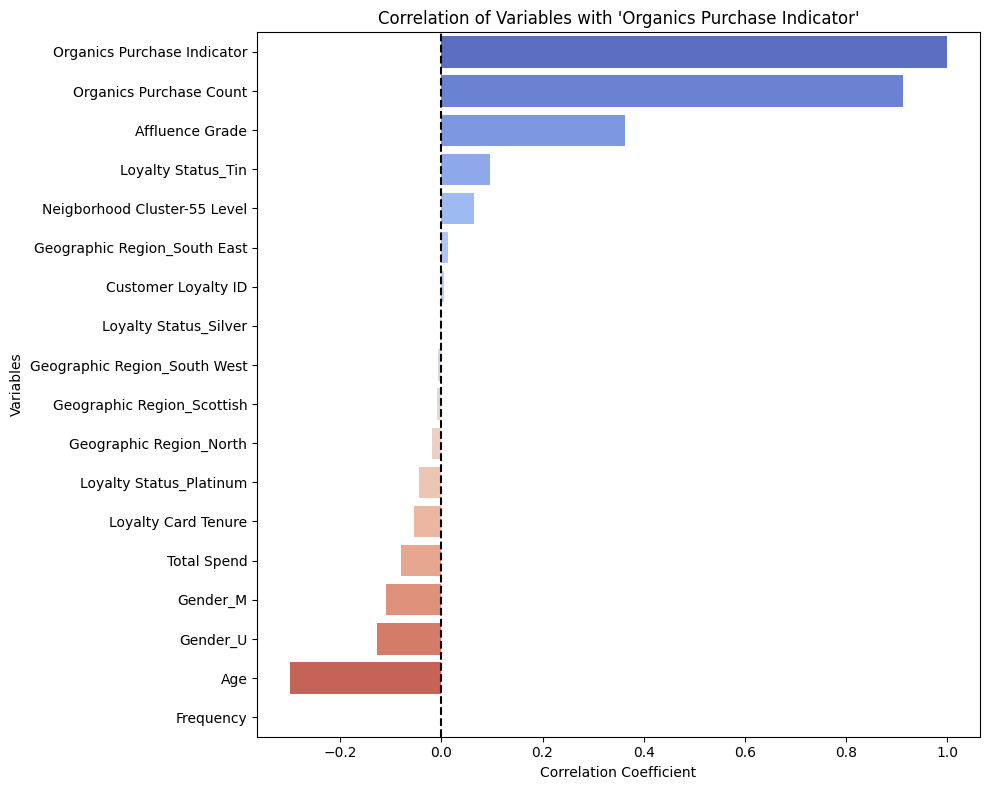

In [43]:
# Plot the correlations with 'Organics Purchase Indicator'
plt.figure(figsize=(10, 8))
sns.barplot(x=correlations.values, y=correlations.index, hue=correlations.index, palette='coolwarm', legend=False)
plt.title("Correlation of Variables with 'Organics Purchase Indicator'")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Variables")
plt.axvline(x=0, color='black', linestyle='--')
plt.tight_layout()
plt.show()